# Fase C: Modelos supervisados para hospitalización por dengue

**Variable objetivo:** `PAC_HOS` (`1` = hospitalización registrada, `2` = no hospitalización)

## Pregunta de negocio
¿Qué tan bien puede anticiparse, a partir de la información disponible en el registro de notificación, si un caso tendrá hospitalización registrada? El resultado sirve para priorizar revisión y vigilancia, pero no sustituye una decisión clínica.

## Alcance y decisiones
Se comparan Regresión Logística, Árbol de Decisión y Random Forest. El conjunto de prueba se separa antes de ajustar cualquier imputador, codificador, escalador o modelo. `AJUSTE` se excluye porque puede ser un campo posterior a la notificación; `nom_est_f_caso` se excluye por su alta cardinalidad y posible relación con el resultado; municipio se excluye para evitar una representación demasiado dispersa y dependiente del territorio. La clase positiva es hospitalización. Para atender el desbalance aproximado 38/62 se usa `class_weight`, que asigna un peso mayor a la clase minoritaria y evita que el modelo favorezca excesivamente la clase mayoritaria.

Los resultados describen asociaciones y capacidad predictiva dentro de este conjunto de registros. No son tasas poblacionales ni prueban causalidad; el AUC esperado es moderado y debe validarse con datos nuevos.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
    precision_score, precision_recall_curve, recall_score, roc_auc_score, roc_curve,
    classification_report)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
TARGET = "hospitalizado"
pd.set_option("display.max_columns", 100)

## 1. Carga y control de calidad

Los modelos supervisados (secciones 1 a 14) parten del consolidado del P1 (`dengue_consolidado.parquet`) y aplican su propia limpieza dentro de un `Pipeline` (imputación, codificación y escalado ajustados solo con train). No se usa `datos_limpios.parquet` aquí porque ese archivo ya viene transformado (dummies y variables escaladas, sin `EDAD`, `UNI_MED` ni `SEMANA` originales) y el pipeline necesita las columnas crudas. Las secciones 15 y 16 sí usan `datos_limpios.parquet` de la Fase B. Ambas partes comparten exactamente la misma partición train/test (mismo `train_test_split` estratificado con `random_state=42` sobre las mismas filas), así que las métricas de test son comparables.

In [2]:
ruta_parquet = Path("../datos/procesados/dengue_consolidado.parquet")
if not ruta_parquet.exists():
    raise FileNotFoundError(f"No se encontro el consolidado en: {ruta_parquet.resolve()}")

origen = "dengue_consolidado.parquet"

df = pd.read_parquet(ruta_parquet).copy()
columnas_minimas = {"PAC_HOS", "EDAD", "UNI_MED", "ANO", "SEMANA"}
faltantes = columnas_minimas - set(df.columns)
if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {sorted(faltantes)}")

print(f"Origen: {ruta_parquet.resolve()} ({origen})")
print(f"Registros leidos: {len(df):,}")
display(df.head(3))

Origen: C:\Users\Sanatiago Hernadez\Desktop\grupo-4-p1\datos\procesados\dengue_consolidado.parquet (dengue_consolidado.parquet)
Registros leidos: 581,071


,SEMANA,ANO,EDAD,UNI_MED,SEXO,COD_DPTO_O,COD_MUN_O,AREA,TIP_SS,PER_ETN,estrato,GP_DESPLAZ,GP_MIGRANT,GP_GESTAN,TIP_CAS,PAC_HOS,AJUSTE,nom_est_f_caso,Departamento_ocurrencia,Municipio_ocurrencia
0,11,2022,6,1,M,44,1,1,S,6,2,2,2,2,3,1,0,Confirmado por laboratorio,GUAJIRA,RIOHACHA
1,33,2022,37,1,M,54,1,1,C,6,1,2,2,2,3,1,0,Confirmado por laboratorio,NORTE SANTANDER,CUCUTA
2,16,2022,10,1,M,20,750,1,S,6,1,2,2,2,2,1,3,Confirmado por laboratorio,CESAR,SAN DIEGO


In [3]:
# Normalizacion del objetivo sin modificar el parquet original.
pac_hos = pd.to_numeric(df["PAC_HOS"], errors="coerce")
df = df.loc[pac_hos.isin([1, 2])].copy()
df[TARGET] = (pd.to_numeric(df["PAC_HOS"], errors="coerce") == 1).astype("int8")

# Edad en anos: UNI_MED=1 representa anos; las demas unidades corresponden
# a edades inferiores a un ano y se conservan como 0 anos para modelar.
edad = pd.to_numeric(df["EDAD"], errors="coerce")
unidad = pd.to_numeric(df["UNI_MED"], errors="coerce")
df["edad_anios"] = np.where(unidad.eq(1), edad, 0.0)
df.loc[~df["edad_anios"].between(0, 100), "edad_anios"] = np.nan

print("Distribucion de la variable objetivo:")
tabla_objetivo = df[TARGET].value_counts().rename(index={0: "No hospitalizado", 1: "Hospitalizado"}).to_frame("registros")
tabla_objetivo["porcentaje"] = 100 * tabla_objetivo["registros"] / len(df)
display(tabla_objetivo)
assert df[TARGET].nunique() == 2
assert df["edad_anios"].dropna().between(0, 100).all()

Distribucion de la variable objetivo:


,registros,porcentaje
hospitalizado,,
No hospitalizado,357711,61.560635
Hospitalizado,223360,38.439365


**Control de calidad:** los valores de edad mayores de 100 años se convierten en faltantes y serán imputados dentro del pipeline. Esta decisión evita borrar registros completos por un error puntual y evita que el valor implausible influya en el ajuste.

## 2. División anti-leakage

La partición estratificada 80/20 se realiza antes de entrenar cualquier transformación. La estratificación conserva aproximadamente la misma proporción de hospitalizados en train y test. El test se toca únicamente en la evaluación final.

In [4]:
columnas_excluidas = ["PAC_HOS", TARGET, "AJUSTE", "nom_est_f_caso", "COD_MUN_O", "Municipio_ocurrencia", "EDAD", "UNI_MED"]
columnas_modelo = [c for c in df.columns if c not in columnas_excluidas]
X = df[columnas_modelo].copy()
y = df[TARGET].copy()
for columna in [c for c in ["ANO", "SEMANA", "edad_anios"] if c in X.columns]:
    X[columna] = pd.to_numeric(X[columna], errors="coerce")
for columna in [c for c in X.columns if c not in ["ANO", "SEMANA", "edad_anios"]]:
    X[columna] = X[columna].astype("string")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

indices_train = set(X_train.index)
indices_test = set(X_test.index)
assert indices_train.isdisjoint(indices_test)
assert len(indices_train | indices_test) == len(df)
print(f"Train: {len(X_train):,} filas | positivos: {y_train.mean():.3%}")
print(f"Test:  {len(X_test):,} filas | positivos: {y_test.mean():.3%}")
print("Verificacion anti-leakage: OK, no hay indices compartidos.")

Train: 464,856 filas | positivos: 38.439%
Test:  116,215 filas | positivos: 38.439%
Verificacion anti-leakage: OK, no hay indices compartidos.


## 3. Preprocesamiento reproducible

Las variables numéricas (`ANO`, `SEMANA`, `edad_anios`) se imputan con mediana y se estandarizan. Los códigos y categorías sin orden se imputan con moda y se codifican One-Hot. `estrato` se trata como ordinal, con categorías 1 a 6 y código `-1` para categorías desconocidas. Todos estos pasos viven dentro de cada `Pipeline`, por lo que `fit` solo ocurre sobre train durante la validación cruzada.

In [5]:
columnas_numericas = [c for c in ["ANO", "SEMANA", "edad_anios"] if c in X.columns]
columnas_ordinales = ["estrato"] if "estrato" in X.columns else []
columnas_categoricas = [c for c in X.columns if c not in columnas_numericas + columnas_ordinales]

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([
            ("imputacion", SimpleImputer(strategy="median")),
            ("escalado", StandardScaler()),
        ]), columnas_numericas),
        ("ordinales", Pipeline([
            ("imputacion", SimpleImputer(strategy="most_frequent")),
            ("codificacion", OrdinalEncoder(categories=[["1", "2", "3", "4", "5", "6"]], handle_unknown="use_encoded_value", unknown_value=-1)),
        ]), columnas_ordinales),
        ("categoricas", Pipeline([
            ("imputacion", SimpleImputer(strategy="most_frequent")),
            ("codificacion", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), columnas_categoricas),
    ],
    remainder="drop",
)
print("Numericas:", columnas_numericas)
print("Ordinales:", columnas_ordinales)
print("Categoricas:", columnas_categoricas)
print("AJUSTE excluida:", "AJUSTE" not in X.columns)

Numericas: ['ANO', 'SEMANA', 'edad_anios']
Ordinales: ['estrato']
Categoricas: ['SEXO', 'COD_DPTO_O', 'AREA', 'TIP_SS', 'PER_ETN', 'GP_DESPLAZ', 'GP_MIGRANT', 'GP_GESTAN', 'TIP_CAS', 'Departamento_ocurrencia']
AJUSTE excluida: True


## 4. Entrenamiento y ajuste de hiperparámetros

La métrica de selección es ROC-AUC porque evalúa la capacidad de ordenar casos positivos y negativos en distintos umbrales. La validación cruzada de tres particiones ocurre únicamente dentro de `X_train`/`y_train`. `class_weight="balanced"` asigna un peso mayor a la clase minoritaria según su frecuencia. Así, los errores sobre los casos hospitalizados tienen mayor influencia durante el ajuste y se evita que Accuracy sea la única señal de calidad.

Además de precisión e interpretabilidad, se considera la velocidad: la celda de entrenamiento reporta el tiempo total de ajuste de cada modelo, incluyendo su búsqueda de hiperparámetros.

In [6]:
modelos = {
    "Regresion Logistica": (
        LogisticRegression(class_weight="balanced", max_iter=1000, solver="liblinear", random_state=RANDOM_STATE),
        {"modelo__C": [0.1, 1.0, 10.0]},
    ),
    "Arbol de Decision": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"modelo__max_depth": [5, 10, None], "modelo__min_samples_leaf": [10]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE),
        {"modelo__n_estimators": [50], "modelo__max_depth": [15], "modelo__min_samples_leaf": [1]},
    ),
}

import time

ajustes = {}
tiempos_entrenamiento = {}
for nombre, (modelo, parametros) in modelos.items():
    pipeline = Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])
    print(f"Iniciando {nombre}...")
    busqueda = GridSearchCV(
        pipeline, parametros, scoring="roc_auc", cv=3, n_jobs=-1, refit=True,
        return_train_score=False, verbose=2, pre_dispatch="2*n_jobs",
    )
    inicio = time.perf_counter()
    busqueda.fit(X_train, y_train)
    tiempos_entrenamiento[nombre] = time.perf_counter() - inicio
    ajustes[nombre] = busqueda
    print(f"{nombre}: AUC CV={busqueda.best_score_:.4f} | parametros={busqueda.best_params_}")

print("Tiempos de entrenamiento (incluye validación cruzada y ajuste): "
      + " | ".join(f"{nombre}: {segundos:.2f} s" for nombre, segundos in tiempos_entrenamiento.items()))

assert set(ajustes) == set(modelos)

Iniciando Regresion Logistica...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Regresion Logistica: AUC CV=0.6672 | parametros={'modelo__C': 1.0}
Iniciando Arbol de Decision...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Arbol de Decision: AUC CV=0.6672 | parametros={'modelo__max_depth': 10, 'modelo__min_samples_leaf': 10}
Iniciando Random Forest...
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Random Forest: AUC CV=0.6932 | parametros={'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 50}
Tiempos de entrenamiento (incluye validación cruzada y ajuste): Regresion Logistica: 84.44 s | Arbol de Decision: 123.55 s | Random Forest: 596.90 s


**Lectura metodológica:** el mejor AUC de validación cruzada no se interpreta como resultado final. La comparación válida se hará una sola vez sobre `X_test`, que no participó en la selección de hiperparámetros.

## 5. Evaluación final en test

Se reportan Accuracy, Precision, Recall, F1 y ROC-AUC. Precision indica qué proporción de las alertas de hospitalización fue correcta; Recall indica qué proporción de las hospitalizaciones registradas fue detectada; F1 equilibra ambas.

In [7]:
resultados = []
predicciones = {}
for nombre, busqueda in ajustes.items():
    modelo = busqueda.best_estimator_
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    predicciones[nombre] = {"pred": pred, "prob": prob}
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

tabla_metricas = pd.DataFrame(resultados).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(tabla_metricas.style.format({c: "{:.4f}" for c in tabla_metricas.columns if c != "Modelo"}))
for nombre, valores in predicciones.items():
    print(f"\n{nombre}\n", classification_report(y_test, valores["pred"], target_names=["No hospitalizado", "Hospitalizado"], digits=4, zero_division=0))

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.6462,0.5361,0.5915,0.5624,0.6900
1,Arbol de Decision,0.6303,0.5175,0.5631,0.5394,0.6634
2,Regresion Logistica,0.6232,0.5087,0.5751,0.5399,0.6630



Regresion Logistica
                   precision    recall  f1-score   support

No hospitalizado     0.7112    0.6532    0.6810     71543
   Hospitalizado     0.5087    0.5751    0.5399     44672

        accuracy                         0.6232    116215
       macro avg     0.6100    0.6142    0.6104    116215
    weighted avg     0.6334    0.6232    0.6267    116215


Arbol de Decision
                   precision    recall  f1-score   support

No hospitalizado     0.7113    0.6722    0.6912     71543
   Hospitalizado     0.5175    0.5631    0.5394     44672

        accuracy                         0.6303    116215
       macro avg     0.6144    0.6177    0.6153    116215
    weighted avg     0.6368    0.6303    0.6328    116215


Random Forest
                   precision    recall  f1-score   support

No hospitalizado     0.7273    0.6803    0.7031     71543
   Hospitalizado     0.5361    0.5915    0.5624     44672

        accuracy                         0.6462    116215
      

**Insight:** la tabla debe leerse priorizando la métrica alineada con el uso. Si el objetivo es no perder casos hospitalizados, Recall tiene prioridad; si los recursos de seguimiento son limitados, Precision gana importancia. Accuracy por sí sola puede ser engañosa ante el desbalance.

## 6. Matrices de confusión

La matriz muestra aciertos y errores en el umbral por defecto de 0.5. En un despliegue real el umbral debería elegirse con costos de falsos negativos y falsos positivos definidos por salud pública.

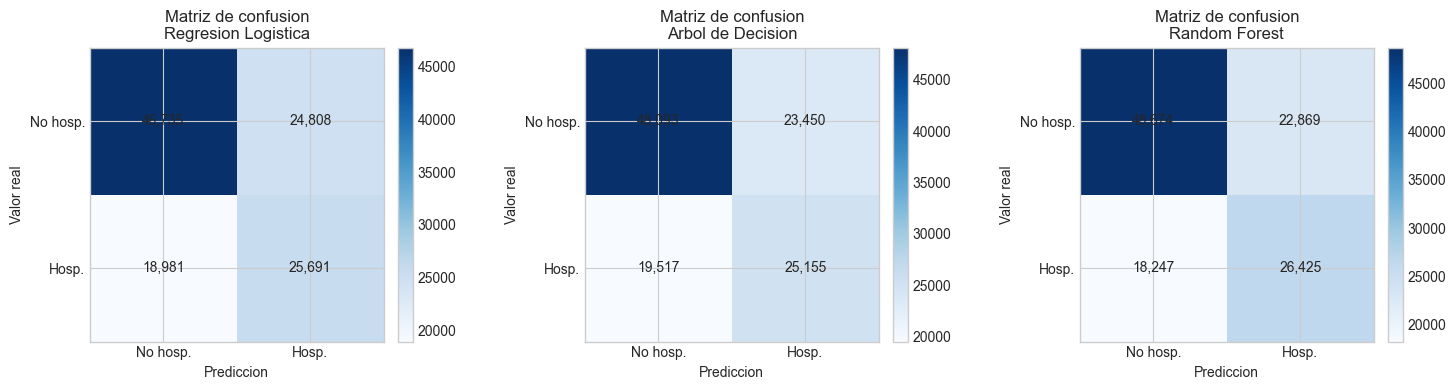

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, valores) in zip(axes, predicciones.items()):
    matriz = confusion_matrix(y_test, valores["pred"], labels=[0, 1])
    imagen = ax.imshow(matriz, cmap="Blues")
    ax.set_title(f"Matriz de confusion\n{nombre}")
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Valor real")
    ax.set_xticks([0, 1], ["No hosp.", "Hosp."])
    ax.set_yticks([0, 1], ["No hosp.", "Hosp."])
    for fila in range(2):
        for columna in range(2):
            ax.text(columna, fila, f"{matriz[fila, columna]:,}", ha="center", va="center")
    fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

**Insight:** los falsos negativos son registros hospitalizados clasificados como no hospitalizados y representan el error más sensible si el modelo se usa para priorizar seguimiento. La matriz permite decidir si conviene ajustar el umbral para aumentar Recall, aceptando posiblemente más falsas alarmas.

## 7. Curvas ROC comparativas

La curva ROC reúne todos los umbrales posibles. La línea diagonal representa un clasificador sin capacidad de discriminación; cuanto más arriba quede una curva, mejor separa los dos grupos en promedio.

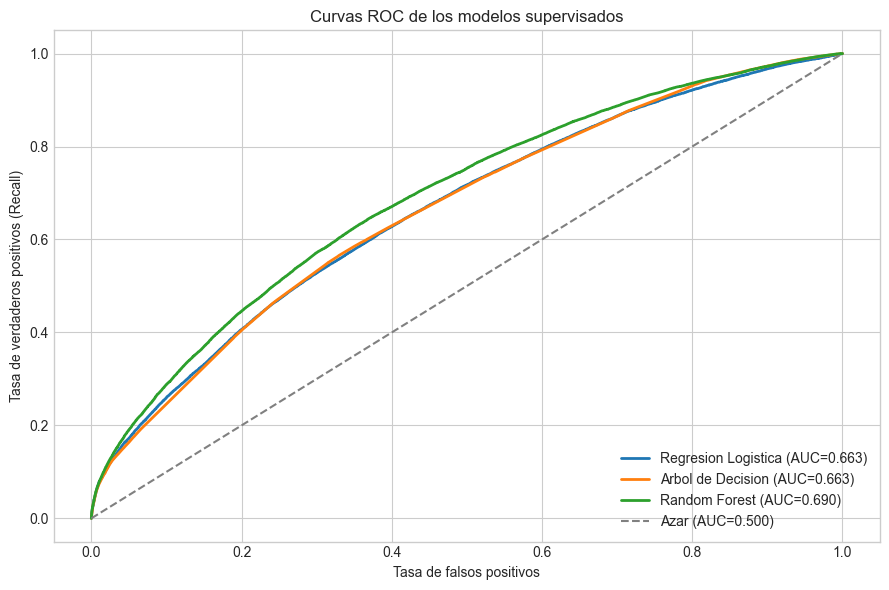

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
for nombre, valores in predicciones.items():
    fpr, tpr, _ = roc_curve(y_test, valores["prob"])
    auc = roc_auc_score(y_test, valores["prob"])
    ax.plot(fpr, tpr, linewidth=2, label=f"{nombre} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0.500)")
ax.set_title("Curvas ROC de los modelos supervisados")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Insight:** un AUC cercano a 0.70 representa discriminación útil pero moderada, no una predicción perfecta. El modelo puede apoyar una priorización, pero la revisión clínica y la incorporación de variables externas, como clima y población DANE, siguen siendo necesarias.

## 8. Comparación visual de métricas

Este gráfico facilita comunicar el compromiso entre precisión, cobertura y discriminación de cada alternativa.

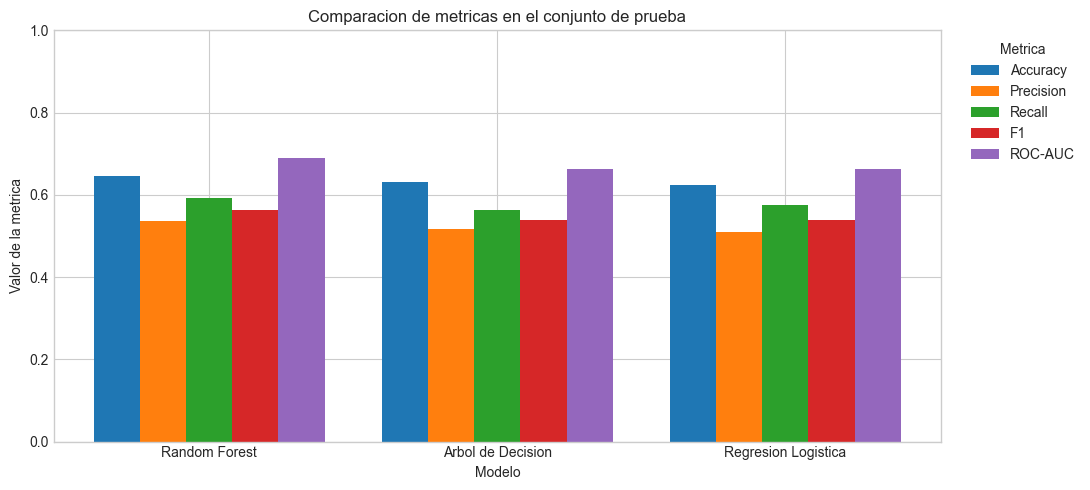

In [10]:
metricas_largas = tabla_metricas.melt(id_vars="Modelo", var_name="Metrica", value_name="Valor")
fig, ax = plt.subplots(figsize=(11, 5))
modelos_grafico = metricas_largas["Modelo"].unique()
metricas_grafico = metricas_largas["Metrica"].unique()
ancho = 0.8 / len(metricas_grafico)
posiciones = np.arange(len(modelos_grafico))
for indice, metrica in enumerate(metricas_grafico):
    valores = metricas_largas[metricas_largas["Metrica"] == metrica].set_index("Modelo").reindex(modelos_grafico)["Valor"]
    ax.bar(posiciones + indice * ancho, valores, width=ancho, label=metrica)
ax.set_xticks(posiciones + ancho * (len(metricas_grafico) - 1) / 2, modelos_grafico)
ax.set_title("Comparacion de metricas en el conjunto de prueba")
ax.set_xlabel("Modelo")
ax.set_ylabel("Valor de la metrica")
ax.set_ylim(0, 1)
ax.legend(title="Metrica", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:** no existe un ganador universal: la selección depende del costo operativo de cada error. Para una primera versión se recomienda informar el modelo con mayor ROC-AUC y, en paralelo, revisar Recall y Precision antes de fijar un umbral de uso.

## 9. Importancia de variables

Se muestran las variables transformadas más influyentes del mejor modelo según ROC-AUC. En Random Forest la importancia es reducción media de impureza; en modelos lineales se usa el valor absoluto del coeficiente. Estas medidas son asociativas y no deben presentarse como efectos causales.

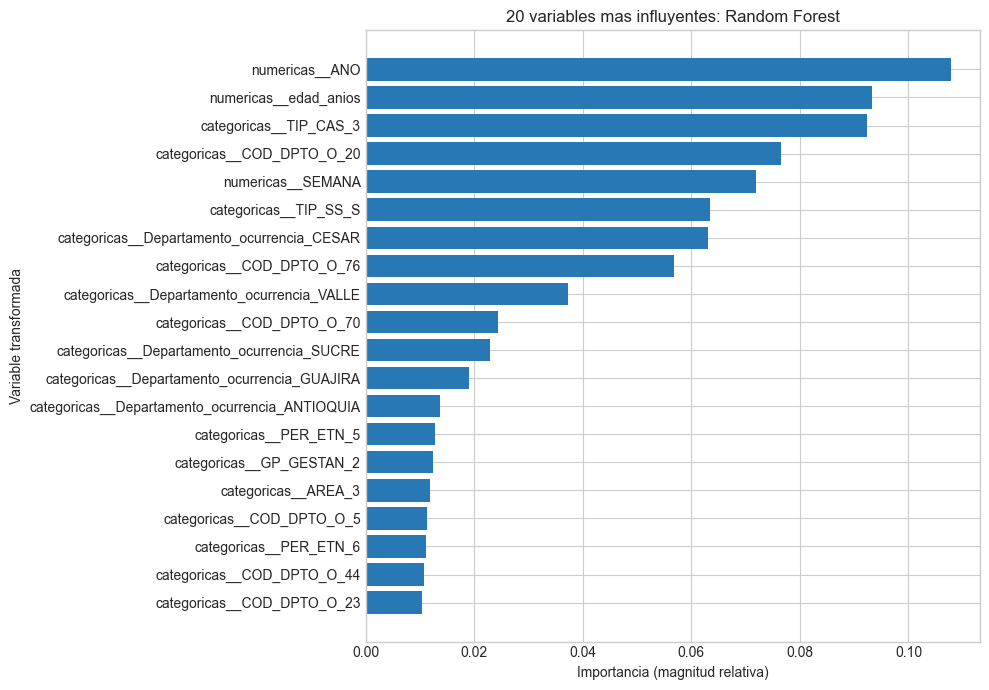

,variable,importancia
0,numericas__ANO,0.107791
2,numericas__edad_anios,0.093263
52,categoricas__TIP_CAS_3,0.092377
10,categoricas__COD_DPTO_O_20,0.076496
1,numericas__SEMANA,0.071952
43,categoricas__TIP_SS_S,0.063404
63,categoricas__Departamento_ocurrencia_CESAR,0.063153
26,categoricas__COD_DPTO_O_76,0.056906
83,categoricas__Departamento_ocurrencia_VALLE,0.037376
24,categoricas__COD_DPTO_O_70,0.024337


In [11]:
mejor_nombre = tabla_metricas.iloc[0]["Modelo"]
mejor_pipeline = ajustes[mejor_nombre].best_estimator_
preparado = mejor_pipeline.named_steps["preprocesamiento"]
modelo_final = mejor_pipeline.named_steps["modelo"]
nombres_variables = preparado.get_feature_names_out()
if hasattr(modelo_final, "feature_importances_"):
    importancias = modelo_final.feature_importances_
else:
    importancias = np.abs(modelo_final.coef_[0])

importancia = pd.DataFrame({"variable": nombres_variables, "importancia": importancias})
importancia = importancia.sort_values("importancia", ascending=False).head(20).sort_values("importancia")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importancia["variable"], importancia["importancia"], color="#2878b5")
ax.set_title(f"20 variables mas influyentes: {mejor_nombre}")
ax.set_xlabel("Importancia (magnitud relativa)")
ax.set_ylabel("Variable transformada")
plt.tight_layout()
plt.show()
display(importancia.sort_values("importancia", ascending=False).head(10))

**Insight:** las variables destacadas indican qué señales utiliza el modelo para separar los registros en este dataset, no cuáles causan hospitalización. Las categorías territoriales deben interpretarse con cuidado porque pueden capturar diferencias de notificación, acceso o calidad del registro.

## 10. Elección, limitaciones y trazabilidad

Se selecciona Random Forest como modelo final preliminar porque obtuvo el mayor ROC-AUC, Recall y F1 en la evaluación aleatoria. Esta decisión debe confirmarse con la evaluación temporal, la calibración y el costo de los errores. Regresión Logística se conserva como alternativa más interpretable, porque permite explicar la dirección y magnitud relativa de sus coeficientes. La decisión final no depende de una sola cifra.

**Velocidad:** Random Forest es el más lento: su ajuste (validación cruzada + reentrenamiento) tomó unos 597 s, frente a unos 84 s de Regresión Logística y 124 s del Árbol de Decisión, es decir, unas 7 veces más que Regresión Logística. Aun así, el costo se paga una sola vez al entrenar; predecir sobre un caso nuevo es casi inmediato, y la ganancia de ROC-AUC (0.690 frente a 0.663 en test) justifica ese tiempo para un uso de priorización que no requiere reentrenar en tiempo real. Si el modelo tuviera que reentrenarse con mucha frecuencia o explicarse caso a caso, Regresión Logística sería la alternativa por velocidad e interpretabilidad.

La línea base de clase mayoritaria confirma si el modelo agrega valor frente a predecir siempre la clase dominante; por el desbalance, no basta con comparar Accuracy.

Limitaciones: el objetivo es hospitalización registrada, no gravedad clínica; el dataset no contiene denominadores poblacionales; puede existir deriva temporal entre 2022 y 2025; las variables disponibles pueden reflejar decisiones de notificación; y el test es una evaluación interna. Como mejoras se proponen validación temporal, calibración y ajuste de umbral, datos de población y clima, más variables clínicas disponibles antes de la hospitalización y evaluación externa.

## 10.1. Controles adicionales de calidad y línea base

Se diagnostican duplicados y se compara contra una estrategia que siempre predice la clase mayoritaria. No se eliminan duplicados automáticamente: sin un identificador de paciente, dos filas idénticas podrían corresponder a notificaciones diferentes. Por ello, se conservan en el análisis principal y se reportan como una limitación de calidad de datos, no como evidencia de pacientes repetidos.

In [12]:
diagnostico_modelado = pd.DataFrame({
    "registros": [len(df), len(df.drop_duplicates()), int(df.duplicated().sum())],
    "porcentaje": [100, 100 * len(df.drop_duplicates()) / len(df), 100 * df.duplicated().mean()],
}, index=["Total", "Sin duplicados exactos", "Duplicados exactos"])
display(diagnostico_modelado.round(2))
mayoritaria = int(y_train.mode().iloc[0])
pred_mayoritaria = np.full(len(y_test), mayoritaria, dtype="int8")
linea_base = pd.DataFrame([{
    "Modelo": "Linea base: clase mayoritaria",
    "Accuracy": accuracy_score(y_test, pred_mayoritaria),
    "Precision": precision_score(y_test, pred_mayoritaria, zero_division=0),
    "Recall": recall_score(y_test, pred_mayoritaria, zero_division=0),
    "F1": f1_score(y_test, pred_mayoritaria, zero_division=0),
    "ROC-AUC": 0.5,
}])
comparacion_linea_base = pd.concat([linea_base, tabla_metricas], ignore_index=True)
display(comparacion_linea_base.style.format({c: "{:.4f}" for c in comparacion_linea_base.columns if c != "Modelo"}))

,registros,porcentaje
Total,581071,100.00
Sin duplicados exactos,560617,96.48
Duplicados exactos,20454,3.52


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Linea base: clase mayoritaria,0.6156,0.0000,0.0000,0.0000,0.5000
1,Random Forest,0.6462,0.5361,0.5915,0.5624,0.6900
2,Arbol de Decision,0.6303,0.5175,0.5631,0.5394,0.6634
3,Regresion Logistica,0.6232,0.5087,0.5751,0.5399,0.6630


**Insight:** Accuracy por sí sola puede ser engañosa ante el desbalance. La línea base comprueba que los modelos agregan capacidad de discriminación más allá de predecir siempre la clase dominante.

## 11. Precision-Recall y selección del umbral

La curva ROC compara el ordenamiento global, pero Precision-Recall es especialmente informativa para detectar la clase positiva. El umbral 0.5 no se asume óptimo: se selecciona con una validación interna separada de X_train y luego se aplica una sola vez a X_test.

,Umbral,Precision,Recall,F1
0,0.2000,0.3860,0.9990,0.5569
1,0.2500,0.3927,0.9929,0.5628
2,0.3000,0.4077,0.9679,0.5737
3,0.3500,0.4213,0.9446,0.5827
4,0.4000,0.4406,0.9008,0.5917
5,0.4500,0.4800,0.7868,0.5962
6,0.5000,0.5454,0.5955,0.5694
7,0.5500,0.6012,0.4124,0.4892
8,0.6000,0.6561,0.2699,0.3825
9,0.6500,0.7249,0.1770,0.2846


Resultado del umbral seleccionado en test: {'Umbral seleccionado': 0.45, 'Precision test': 0.4784, 'Recall test': 0.7772, 'F1 test': 0.5923}


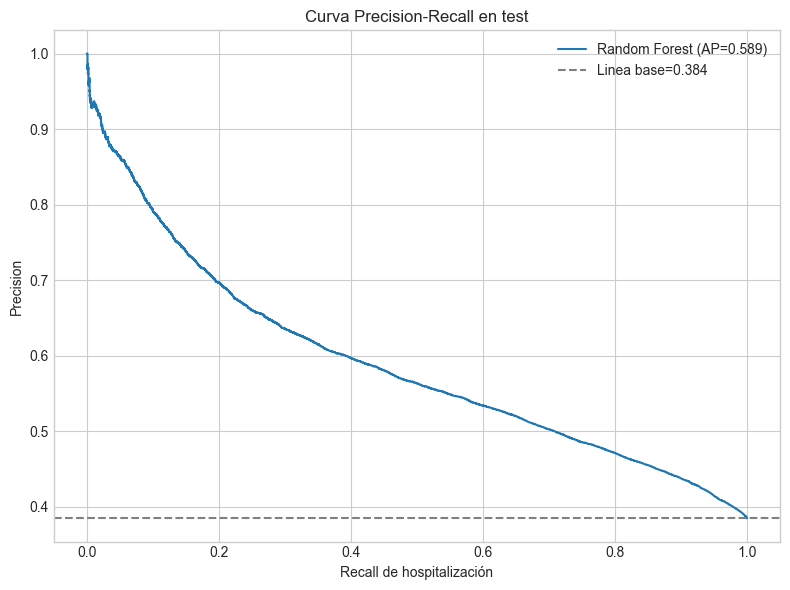

In [13]:
nombre_umbral = mejor_nombre
pipeline_umbral = clone(ajustes[nombre_umbral].best_estimator_)
X_subtrain, X_validacion, y_subtrain, y_validacion = train_test_split(X_train, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE)
pipeline_umbral.fit(X_subtrain, y_subtrain)
prob_validacion = pipeline_umbral.predict_proba(X_validacion)[:, 1]
umbrales = np.arange(0.20, 0.81, 0.05)
filas_umbral = []
for umbral in umbrales:
    pred_validacion = (prob_validacion >= umbral).astype(int)
    filas_umbral.append({"Umbral": umbral, "Precision": precision_score(y_validacion, pred_validacion, zero_division=0), "Recall": recall_score(y_validacion, pred_validacion, zero_division=0), "F1": f1_score(y_validacion, pred_validacion, zero_division=0)})
tabla_umbral = pd.DataFrame(filas_umbral)
umbral_elegido = float(tabla_umbral.loc[tabla_umbral["F1"].idxmax(), "Umbral"])
pred_test_umbral = (predicciones[nombre_umbral]["prob"] >= umbral_elegido).astype(int)
resultado_umbral = {"Umbral seleccionado": umbral_elegido, "Precision test": precision_score(y_test, pred_test_umbral, zero_division=0), "Recall test": recall_score(y_test, pred_test_umbral, zero_division=0), "F1 test": f1_score(y_test, pred_test_umbral, zero_division=0)}
display(tabla_umbral.style.format({c: "{:.4f}" for c in tabla_umbral.columns}))
print("Resultado del umbral seleccionado en test:", {k: round(v, 4) if isinstance(v, float) else v for k, v in resultado_umbral.items()})
precision_curve, recall_curve, _ = precision_recall_curve(y_test, predicciones[nombre_umbral]["prob"])
average_precision = average_precision_score(y_test, predicciones[nombre_umbral]["prob"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_curve, precision_curve, label=f"{nombre_umbral} (AP={average_precision:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"Linea base={y_test.mean():.3f}")
ax.set_title("Curva Precision-Recall en test")
ax.set_xlabel("Recall de hospitalización")
ax.set_ylabel("Precision")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** un umbral menor puede aumentar Recall y reducir falsos negativos, pero genera más falsos positivos. El umbral se selecciona en una validación interna y no mirando el resultado de test.

## 12. Deriva temporal y validación hacia periodos posteriores

La división aleatoria puede ser optimista cuando hay cambios entre 2022 y 2025. Se reporta la tasa de hospitalización por año y se reserva el último año disponible para una evaluación adicional.

In [14]:
df_temporal = df.copy()
df_temporal["ano_modelo"] = pd.to_numeric(df_temporal["ANO"], errors="coerce")
resumen_temporal = df_temporal.groupby("ano_modelo")[TARGET].agg(registros="size", tasa_hospitalizacion="mean").reset_index()
resumen_temporal["tasa_hospitalizacion"] *= 100
display(resumen_temporal.style.format({"tasa_hospitalizacion": "{:.2f}"}))
anos_validos = sorted(X["ANO"].dropna().unique())
if len(anos_validos) >= 2:
    ano_prueba = anos_validos[-1]
    mascara_train_temporal = X["ANO"] < ano_prueba
    mascara_test_temporal = X["ANO"] == ano_prueba
    X_train_temporal, X_test_temporal = X.loc[mascara_train_temporal], X.loc[mascara_test_temporal]
    y_train_temporal, y_test_temporal = y.loc[mascara_train_temporal], y.loc[mascara_test_temporal]
    modelo_temporal = clone(ajustes[mejor_nombre].best_estimator_)
    modelo_temporal.fit(X_train_temporal, y_train_temporal)
    prob_temporal = modelo_temporal.predict_proba(X_test_temporal)[:, 1]
    pred_temporal = (prob_temporal >= 0.5).astype(int)
    resultado_temporal = pd.DataFrame([{"Periodo de prueba": int(ano_prueba), "Registros train": len(X_train_temporal), "Registros test": len(X_test_temporal), "ROC-AUC": roc_auc_score(y_test_temporal, prob_temporal), "Precision": precision_score(y_test_temporal, pred_temporal, zero_division=0), "Recall": recall_score(y_test_temporal, pred_temporal, zero_division=0), "F1": f1_score(y_test_temporal, pred_temporal, zero_division=0)}])
    display(resultado_temporal.style.format({"ROC-AUC": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}))
    resultado_comparacion = pd.DataFrame([
        {"Evaluacion": "Split aleatorio", "ROC-AUC": tabla_metricas.iloc[0]["ROC-AUC"], "Precision": tabla_metricas.iloc[0]["Precision"], "Recall": tabla_metricas.iloc[0]["Recall"], "F1": tabla_metricas.iloc[0]["F1"]},
        {"Evaluacion": "Split temporal", "ROC-AUC": resultado_temporal.iloc[0]["ROC-AUC"], "Precision": resultado_temporal.iloc[0]["Precision"], "Recall": resultado_temporal.iloc[0]["Recall"], "F1": resultado_temporal.iloc[0]["F1"]},
    ])
    print("Comparacion del modelo final entre evaluacion aleatoria y temporal:")
    display(resultado_comparacion.style.format({c: "{:.4f}" for c in resultado_comparacion.columns if c != "Evaluacion"}))

,ano_modelo,registros,tasa_hospitalizacion
0,2022,63076,52.82
1,2023,113314,44.59
2,2024,292384,33.59
3,2025,112297,36.78


,Periodo de prueba,Registros train,Registros test,ROC-AUC,Precision,Recall,F1
0,2025,468774,112297,0.6691,0.4935,0.5958,0.5399


Comparacion del modelo final entre evaluacion aleatoria y temporal:


,Evaluacion,ROC-AUC,Precision,Recall,F1
0,Split aleatorio,0.6900,0.5361,0.5915,0.5624
1,Split temporal,0.6691,0.4935,0.5958,0.5399


**Interpretación:** la tabla compara el desempeño del modelo final en una partición aleatoria y en un periodo posterior no utilizado para entrenar. Si el resultado temporal cae frente al aleatorio, existe evidencia de deriva o menor generalización hacia datos futuros; en ese caso, el AUC aleatorio no debe presentarse como garantía de desempeño operativo.

## 13. Calibración e interpretabilidad por permutación

ROC-AUC mide ordenamiento, pero no garantiza que una probabilidad de 0.70 corresponda aproximadamente a un 70 % de hospitalizaciones. También se calcula importancia por permutación sobre una muestra de test.

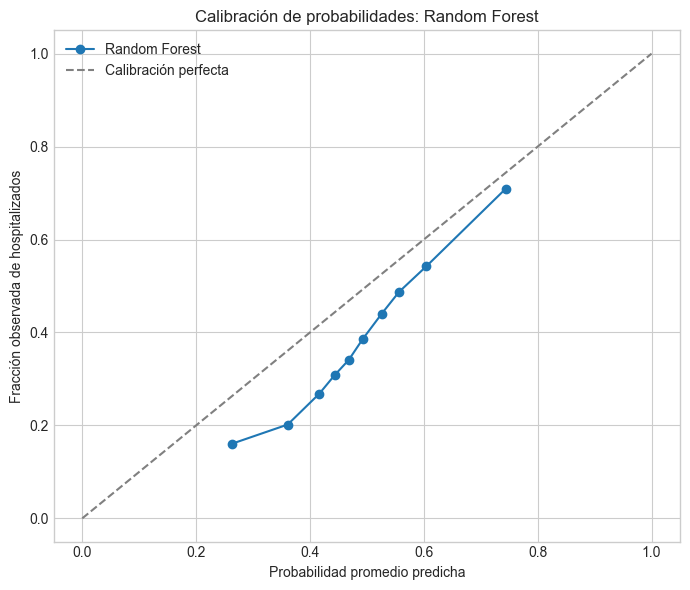

Brier score de Random Forest: 0.2226 (menor es mejor)


,variable,disminucion_auc_promedio,desviacion
3,COD_DPTO_O,0.045499,0.002205
11,TIP_CAS,0.039953,0.001397
12,Departamento_ocurrencia,0.036065,0.001106
1,ANO,0.031633,0.002821
5,TIP_SS,0.018697,0.001321
13,edad_anios,0.011214,0.001102
6,PER_ETN,0.006787,0.000174
0,SEMANA,0.006455,0.001079
4,AREA,0.006330,0.000513
10,GP_GESTAN,0.002317,0.000141


In [15]:
prob_mejor = predicciones[mejor_nombre]["prob"]
fraccion_calibrada, promedio_calibrado = calibration_curve(y_test, prob_mejor, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_test, prob_mejor)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(promedio_calibrado, fraccion_calibrada, marker="o", label=mejor_nombre)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibración perfecta")
ax.set_title(f"Calibración de probabilidades: {mejor_nombre}")
ax.set_xlabel("Probabilidad promedio predicha")
ax.set_ylabel("Fracción observada de hospitalizados")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Brier score de {mejor_nombre}: {brier:.4f} (menor es mejor)")
rng = np.random.RandomState(RANDOM_STATE)
indices_perm = rng.choice(len(X_test), size=min(10000, len(X_test)), replace=False)
perm = permutation_importance(ajustes[mejor_nombre].best_estimator_, X_test.iloc[indices_perm], y_test.iloc[indices_perm], scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
importancia_perm = pd.DataFrame({"variable": X_test.columns, "disminucion_auc_promedio": perm.importances_mean, "desviacion": perm.importances_std}).sort_values("disminucion_auc_promedio", ascending=False).head(15)
display(importancia_perm)

**Insight:** las importancias muestran señales asociadas con el desempeño predictivo, no causas de hospitalización. La calibración y la importancia por permutación complementan la curva ROC y evitan interpretar una única métrica como evidencia suficiente.

## 14. Síntesis final para el informe

- La clase positiva es hospitalización registrada (`PAC_HOS = 1`), no diagnóstico, gravedad ni tasa poblacional.
- Se compararon los tres modelos obligatorios; Random Forest se selecciona preliminarmente por su mejor ROC-AUC, Recall y F1 en la partición aleatoria, sujeto a la validación temporal.
- El pipeline evita ajustar imputación, codificación y escalamiento con el conjunto de prueba.
- La evaluación aleatoria se complementa con la evaluación temporal por la posible deriva entre años; la diferencia entre ambas debe reportarse en el informe.
- La línea base de clase mayoritaria se utiliza como referencia y el umbral debe definirse según el costo de falsos negativos y falsos positivos.
- Se requieren datos nuevos, variables clínicas disponibles antes del evento, población DANE, clima y validación externa para un uso operativo.

In [16]:
# Auditoria final de requisitos.
assert len(ajustes) == 3
assert set(["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).issubset(tabla_metricas.columns)
assert all("modelo" in busqueda.best_estimator_.named_steps for busqueda in ajustes.values())
assert all(busqueda.cv == 3 for busqueda in ajustes.values())
assert "Linea base: clase mayoritaria" in comparacion_linea_base["Modelo"].values
assert "edad_anios" in X.columns and "EDAD" not in X.columns and "UNI_MED" not in X.columns
assert 0 < average_precision <= 1
assert 0 < umbral_elegido < 1
assert "resultado_comparacion" in globals()
print("Validacion final OK")
print(f"Modelo recomendado provisionalmente por ROC-AUC: {mejor_nombre}")
print("El conjunto de prueba solo se utilizo para la evaluacion final.")

Validacion final OK
Modelo recomendado provisionalmente por ROC-AUC: Random Forest
El conjunto de prueba solo se utilizo para la evaluacion final.


## 15. Aprendizaje no supervisado: segmentación de pacientes con K-Means

**Objetivo de negocio:** agrupar los casos de dengue en perfiles de paciente parecidos (edad, régimen de salud, zona, estrato, grupo poblacional) para que la secretaría de salud pueda dirigir acciones distintas a cada perfil, y ver si algún perfil se hospitaliza más.

**Datos:** se usa `datos_limpios.parquet` de la Fase B (ya imputado, codificado y escalado con parámetros de train) y su columna `split`; no se vuelve a dividir ni a escalar. Esta sección es independiente de las anteriores: solo necesita ese archivo y el consolidado del P1 para describir los grupos con sus valores originales.

**Variables del clustering:** solo las sociodemográficas del paciente: `EDAD_ANIOS`, `ESTRATO`, `SEXO`, `TIP_SS`, `AREA`, `PER_ETN`, grupos poblacionales (`GP_*`) y tamaño del municipio (`MUN_LOGCASOS`). Se excluyen:
- `PAC_HOS`: es lo que se quiere explicar; se usa después para perfilar los grupos, no para formarlos.
- Departamento (29 dummies): dominaría las distancias y los grupos serían simplemente regiones; la geografía ya entra resumida por el tamaño del municipio.
- `GRUPO_EDAD`: repite la edad, que ya está como variable continua.
- `ANO`, `SEMANA_*` y `TIP_CAS`: describen cuándo y cómo se notificó el caso, no al paciente.

**Escalado:** K-Means usa distancias, así que todas las variables deben estar en escalas comparables. No se aplica otro `StandardScaler` porque `datos_limpios.parquet` ya viene escalado desde la Fase B con escaladores ajustados solo con train: `MUN_LOGCASOS` con Z-score (`StandardScaler`), `EDAD_ANIOS` con Yeo-Johnson + `RobustScaler` (por los adultos mayores extremos), `ESTRATO` con Min-Max en [0, 1], y las dummies ya están en 0/1. Volver a estandarizar las dummies sería contraproducente: una categoría rara (por ejemplo `TIP_SS_I`, 0.3% de los casos) pasaría a valer decenas de desviaciones y formaría su propio cluster de pocos pacientes.

In [17]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, roc_auc_score
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42

ruta_limpia = next(p for p in (Path("datos_limpios.parquet"), Path("entrega/datos_limpios.parquet")) if p.exists())
ruta_cruda = next(p for p in (Path("../datos/procesados/dengue_consolidado.parquet"),
                              Path("datos/procesados/dengue_consolidado.parquet")) if p.exists())
limpio = pd.read_parquet(ruta_limpia)
crudo = pd.read_parquet(ruta_cruda)

# datos_limpios conserva el orden de filas del consolidado (Fase B usa sort_index):
# se comprueba antes de usar los valores originales para describir los grupos.
assert len(limpio) == len(crudo)
assert np.corrcoef(limpio["ANO"], pd.to_numeric(crudo["ANO"]))[0, 1] > 0.9999
assert (limpio["SEXO_M"].to_numpy() == (crudo["SEXO"].astype(str).str.strip() == "M").to_numpy()).all()

VARS_CLUSTER = ["EDAD_ANIOS", "ESTRATO", "SEXO_M",
                "TIP_SS_E", "TIP_SS_I", "TIP_SS_N", "TIP_SS_P", "TIP_SS_S",
                "AREA_2", "AREA_3",
                "PER_ETN_2", "PER_ETN_3", "PER_ETN_4", "PER_ETN_5", "PER_ETN_6",
                "GP_DESPLAZ", "GP_MIGRANT", "GP_GESTAN", "MUN_LOGCASOS"]

es_train = limpio["split"].eq("train").to_numpy()
X_cl = limpio[VARS_CLUSTER].to_numpy()
X_cl_train, X_cl_test = X_cl[es_train], X_cl[~es_train]

# Submuestra fija de train para Silhouette: su costo crece con n² (465 mil filas no caben en memoria)
rng = np.random.default_rng(SEED)
idx_sil = rng.choice(len(X_cl_train), size=30_000, replace=False)

print("Origen:", ruta_limpia.resolve())
print(f"Train: {len(X_cl_train):,} | test: {len(X_cl_test):,} | variables de clustering: {len(VARS_CLUSTER)}")

Origen: C:\Users\Sanatiago Hernadez\Desktop\grupo-4-p1\entrega\datos_limpios.parquet
Train: 464,856 | test: 116,215 | variables de clustering: 19


### 15.1 Selección de k: método del codo, Silhouette y Davies-Bouldin
K-Means se ajusta **solo con train** para k = 2 a 10. Se miden tres criterios:
- **Inercia (codo):** suma de distancias de cada caso a su centro; siempre baja al subir k, se busca el punto donde deja de bajar mucho.
- **Silhouette** (−1 a 1, mayor es mejor): qué tan separado está cada caso de los otros grupos frente a su propio grupo.
- **Davies-Bouldin** (≥ 0, menor es mejor): parecido promedio entre cada grupo y su grupo más cercano.

Silhouette y Davies-Bouldin se calculan sobre la misma submuestra aleatoria de 30,000 casos de train (Silhouette compara todas las parejas de puntos, imposible con 465 mil filas); con ese tamaño el valor es estable.

,inercia,silhouette,davies_bouldin,caída_inercia_%
k,,,,
2,778492.062,0.269,1.433,NaN
3,677289.562,0.227,1.598,13.0
4,600085.625,0.179,1.759,11.4
5,559333.500,0.166,1.632,6.8
6,524809.625,0.171,1.672,6.2
7,499445.125,0.174,1.712,4.8
8,471418.562,0.180,1.732,5.6
9,453927.562,0.179,1.633,3.7
10,438527.594,0.177,1.636,3.4


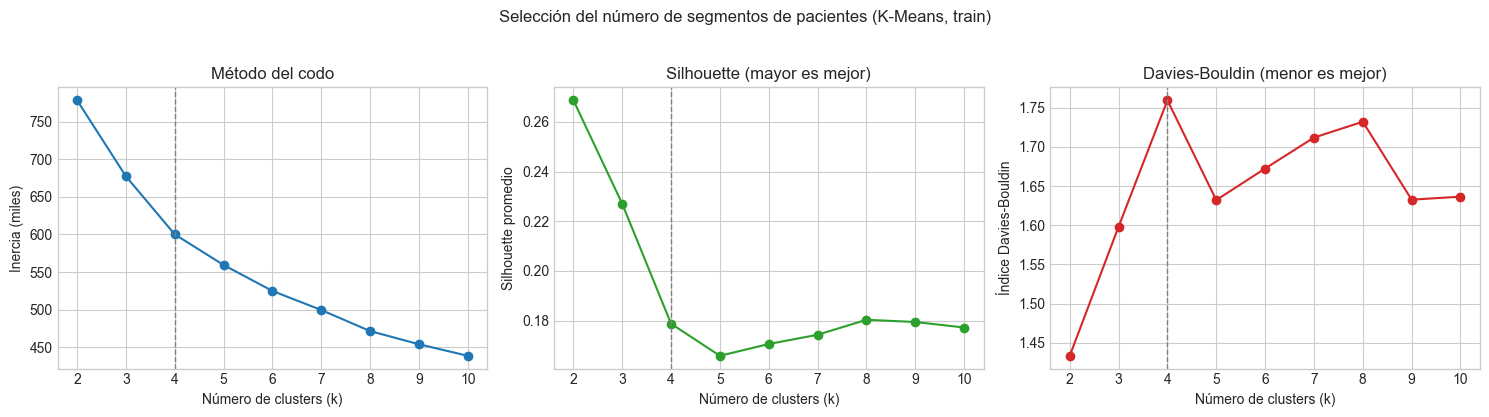

In [18]:
resultados_k = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(X_cl_train)
    etiquetas = km.labels_[idx_sil]
    resultados_k.append({
        "k": k,
        "inercia": km.inertia_,
        "silhouette": silhouette_score(X_cl_train[idx_sil], etiquetas),
        "davies_bouldin": davies_bouldin_score(X_cl_train[idx_sil], etiquetas),
    })
resultados_k = pd.DataFrame(resultados_k).set_index("k")
resultados_k["caída_inercia_%"] = (-resultados_k["inercia"].pct_change() * 100).round(1)
display(resultados_k.round(3))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].plot(resultados_k.index, resultados_k["inercia"] / 1e3, marker="o")
ejes[0].set(title="Método del codo", xlabel="Número de clusters (k)", ylabel="Inercia (miles)")
ejes[1].plot(resultados_k.index, resultados_k["silhouette"], marker="o", color="tab:green")
ejes[1].set(title="Silhouette (mayor es mejor)", xlabel="Número de clusters (k)", ylabel="Silhouette promedio")
ejes[2].plot(resultados_k.index, resultados_k["davies_bouldin"], marker="o", color="tab:red")
ejes[2].set(title="Davies-Bouldin (menor es mejor)", xlabel="Número de clusters (k)", ylabel="Índice Davies-Bouldin")
for eje in ejes:
    eje.axvline(4, ls="--", color="gray", lw=1)
fig.suptitle("Selección del número de segmentos de pacientes (K-Means, train)", y=1.03)
plt.tight_layout()
plt.show()

**Insight:** No hay grupos de pacientes claramente separados: el Silhouette es bajo para cualquier k (0.17-0.27), así que los segmentos son cortes de un continuo, útiles para organizar acciones pero no "tipos" de paciente distintos. Se elige **k = 4** porque ahí se dobla el codo (la inercia cae 13% y 11% hasta k = 4 y después solo ~6% o menos por cada grupo extra) y porque da cuatro perfiles fáciles de explicar. k = 2 tiene mejor Silhouette y Davies-Bouldin, pero solo separa ciudades grandes de municipios pequeños, demasiado general para dirigir acciones; el costo de k = 4 es un Davies-Bouldin algo peor (1.76 frente a 1.43), que se acepta a cambio de interpretabilidad.

In [19]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_cl_train)
cluster = np.empty(len(limpio), dtype=int)
cluster[es_train] = kmeans.labels_
cluster[~es_train] = kmeans.predict(X_cl_test)   # test solo se asigna, no se usa para ajustar

# Perfil con los valores originales del consolidado (más fáciles de leer que los escalados)
edad_anios = np.where(pd.to_numeric(crudo["UNI_MED"]).eq(1), pd.to_numeric(crudo["EDAD"]), 0.0)
# Casos de dengue del municipio en train (lo mismo que resume MUN_LOGCASOS, pero en número de casos)
clave_mun = crudo["COD_DPTO_O"].astype(str) + "-" + crudo["COD_MUN_O"].astype(str)
casos_mun = clave_mun.map(clave_mun[es_train].value_counts()).fillna(0).to_numpy()
perfil_base = pd.DataFrame({
    "cluster": cluster,
    "split": limpio["split"].to_numpy(),
    "hospitalizado": limpio["PAC_HOS"].to_numpy(),
    "edad": np.where(edad_anios > 100, np.nan, edad_anios),
    "menor_18": edad_anios < 18,
    "subsidiado": crudo["TIP_SS"].astype(str).str.strip().eq("S").to_numpy(),
    "contributivo": crudo["TIP_SS"].astype(str).str.strip().eq("C").to_numpy(),
    "cabecera": pd.to_numeric(crudo["AREA"]).eq(1).to_numpy(),
    "estrato_1": pd.to_numeric(crudo["estrato"].astype(str).str.strip(), errors="coerce").eq(1).to_numpy(),
    "hombre": crudo["SEXO"].astype(str).str.strip().eq("M").to_numpy(),
    "casos_municipio": casos_mun,
})

mediana_mun = np.median(casos_mun[es_train])
perfil = perfil_base[perfil_base["split"] == "train"].groupby("cluster").agg(
    casos=("hospitalizado", "size"),
    edad_mediana=("edad", "median"),
    casos_mun_mediana=("casos_municipio", "median"),
    pct_menores_18=("menor_18", "mean"),
    pct_subsidiado=("subsidiado", "mean"),
    pct_contributivo=("contributivo", "mean"),
    pct_cabecera=("cabecera", "mean"),
    pct_estrato_1=("estrato_1", "mean"),
    pct_hombres=("hombre", "mean"),
    pct_mun_grande=("casos_municipio", lambda s: (s >= mediana_mun).mean()),
    tasa_hospitalizacion=("hospitalizado", "mean"),
)
perfil.insert(1, "pct_casos", perfil["casos"] / perfil["casos"].sum())

# Nombre de negocio a partir del perfil (no se escribe a mano para que no dependa del número del cluster)
# Un segmento es de "ciudades grandes" si su municipio típico tiene más casos que la mediana de train

def nombrar(fila, corto=False):
    edad = ("Niños" if corto else "Niños y adolescentes") if fila["pct_menores_18"] >= 0.5 else "Adultos"
    if fila["casos_mun_mediana"] >= mediana_mun:
        entorno = "ciudades grandes" if corto else "ciudades grandes, más contributivo"
    else:
        entorno = "municipios pequeños" if corto else "municipios pequeños y rurales, subsidiado"
    return f"{edad} · {entorno}"

perfil.insert(0, "segmento", perfil.apply(nombrar, axis=1))
assert perfil["segmento"].is_unique, "Dos clusters recibieron el mismo nombre: revisar el perfil"
perfil = perfil.sort_values("tasa_hospitalizacion", ascending=False)
NOMBRES = perfil["segmento"].to_dict()
CORTOS = perfil.apply(nombrar, axis=1, corto=True).to_dict()
print(f"Mediana de casos del municipio de residencia (train): {mediana_mun:,.0f}")

tasa_global = perfil_base.loc[perfil_base["split"] == "train", "hospitalizado"].mean()
print(f"Tasa global de hospitalización (train): {tasa_global:.1%}")
display(perfil.style.format({c: "{:.1%}" for c in perfil.columns if c.startswith(("pct", "tasa"))}
                            | {"casos": "{:,}", "edad_mediana": "{:.0f}", "casos_mun_mediana": "{:,.0f}"}))

Mediana de casos del municipio de residencia (train): 2,724
Tasa global de hospitalización (train): 38.4%


,segmento,casos,pct_casos,edad_mediana,casos_mun_mediana,pct_menores_18,pct_subsidiado,pct_contributivo,pct_cabecera,pct_estrato_1,pct_hombres,pct_mun_grande,tasa_hospitalizacion
cluster,,,,,,,,,,,,,
2,"Niños y adolescentes · municipios pequeños y rurales, subsidiado","129,624",27.9%,10,695,91.3%,73.2%,21.6%,74.5%,68.5%,52.6%,0.4%,45.2%
0,"Niños y adolescentes · ciudades grandes, más contributivo","134,330",28.9%,10,"9,328",92.4%,47.9%,46.0%,94.3%,32.0%,54.7%,98.6%,37.7%
3,"Adultos · municipios pequeños y rurales, subsidiado","97,229",20.9%,37,542,0.5%,56.1%,36.9%,63.6%,60.6%,49.9%,0.7%,36.7%
1,"Adultos · ciudades grandes, más contributivo","103,673",22.3%,34,"9,328",1.7%,20.5%,73.1%,94.2%,17.9%,44.6%,97.5%,32.6%


### 15.2 Perfil de los segmentos

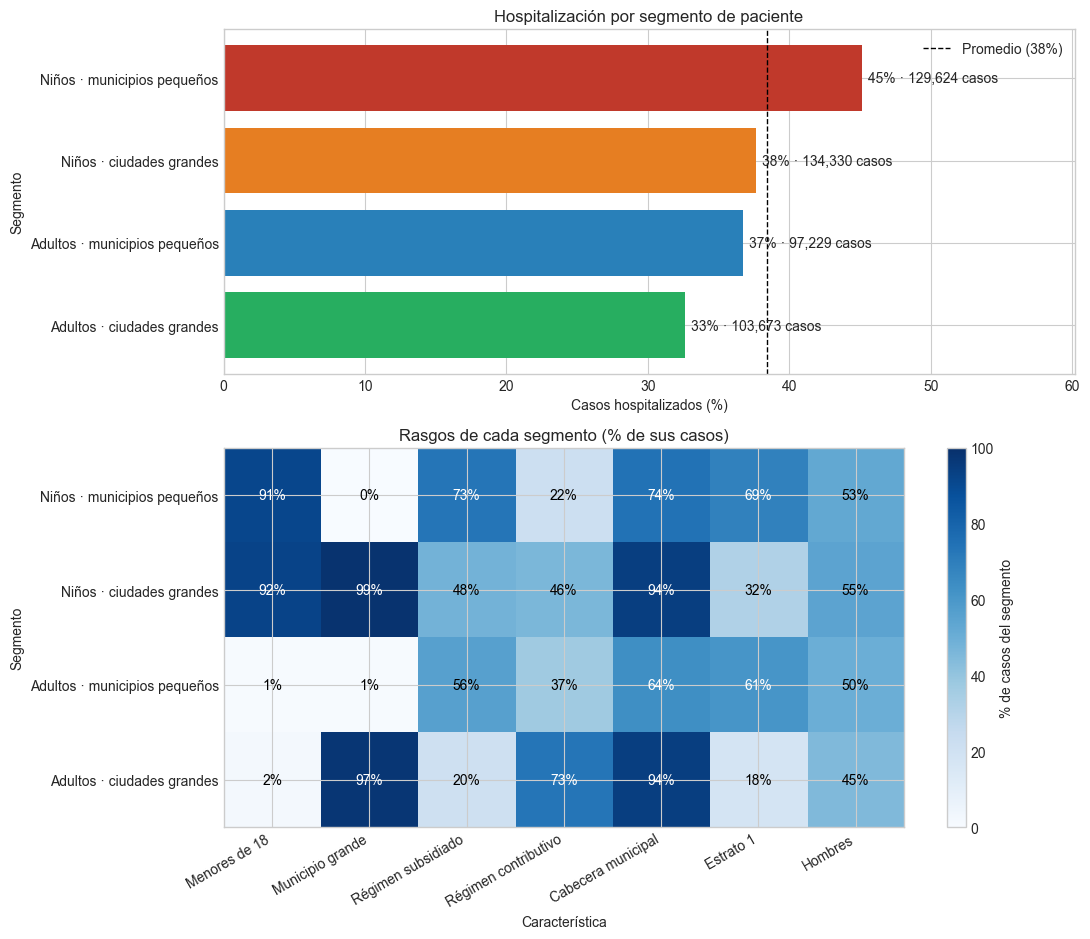

In [20]:
colores = dict(zip(perfil.index, ["#c0392b", "#e67e22", "#2980b9", "#27ae60"]))

fig, ejes = plt.subplots(2, 1, figsize=(11, 9.5), gridspec_kw={"height_ratios": [1, 1.1]})
orden = perfil.index[::-1]
ejes[0].barh([CORTOS[c] for c in orden], perfil.loc[orden, "tasa_hospitalizacion"] * 100,
             color=[colores[c] for c in orden])
ejes[0].axvline(tasa_global * 100, ls="--", color="black", lw=1, label=f"Promedio ({tasa_global:.0%})")
for i, c in enumerate(orden):
    ejes[0].text(perfil.loc[c, "tasa_hospitalizacion"] * 100 + 0.4, i,
                 f"{perfil.loc[c, 'tasa_hospitalizacion']:.0%} · {perfil.loc[c, 'casos']:,} casos", va="center")
ejes[0].set(title="Hospitalización por segmento de paciente", xlabel="Casos hospitalizados (%)", ylabel="Segmento",
            xlim=(0, perfil["tasa_hospitalizacion"].max() * 100 + 15))
ejes[0].legend(loc="upper right")

rasgos = {"pct_menores_18": "Menores de 18", "pct_mun_grande": "Municipio grande", "pct_subsidiado": "Régimen subsidiado",
          "pct_contributivo": "Régimen contributivo", "pct_cabecera": "Cabecera municipal",
          "pct_estrato_1": "Estrato 1", "pct_hombres": "Hombres"}
mapa = perfil[list(rasgos)].rename(columns=rasgos) * 100
im = ejes[1].imshow(mapa.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
ejes[1].set_xticks(range(len(rasgos)), mapa.columns, rotation=30, ha="right")
ejes[1].set_yticks(range(len(mapa)), [CORTOS[c] for c in mapa.index])
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iloc[i, j]
        ejes[1].text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 60 else "black")
ejes[1].set(title="Rasgos de cada segmento (% de sus casos)", xlabel="Característica", ylabel="Segmento")
fig.colorbar(im, ax=ejes[1], label="% de casos del segmento")
plt.tight_layout()
plt.show()

**Insight:** Los segmentos se forman con dos ejes: la **edad** (niños frente a adultos) y el **tamaño del municipio**, que arrastra el régimen y el estrato (en municipios pequeños predominan el régimen subsidiado, el estrato 1 y la zona rural). El segmento de **niños y adolescentes de municipios pequeños** (28% de los casos) se hospitaliza el 45% de las veces, 7 puntos sobre el promedio y 13 más que los adultos de ciudades grandes (33%): es el grupo prioritario para seguimiento clínico, rutas de atención y campañas en temporada alta. 

### 15.3 Visualización de los segmentos con PCA (2 componentes)
Las 19 variables se proyectan en 2 dimensiones con PCA (ajustado con train) para ver si los grupos se separan. Se grafica una submuestra de 8,000 casos para que los puntos no se tapen.

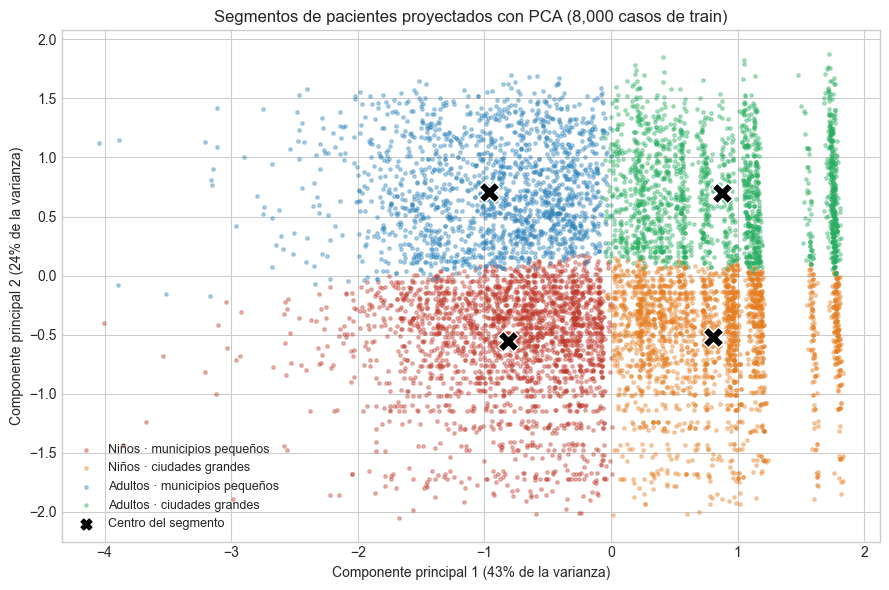

Varianza explicada por las 2 componentes: 66.8%
Variables con más peso en cada componente:
  CP1: MUN_LOGCASOS (+0.97), TIP_SS_S (-0.18), AREA_3 (-0.09)
  CP2: EDAD_ANIOS (+0.99), TIP_SS_S (-0.15), ESTRATO (+0.04)


In [21]:
pca = PCA(n_components=2, random_state=SEED).fit(X_cl_train)
idx_pca = rng.choice(len(X_cl_train), size=8_000, replace=False)
proy = pca.transform(X_cl_train[idx_pca])
lab_pca = kmeans.labels_[idx_pca]
centros = pca.transform(kmeans.cluster_centers_)

fig, eje = plt.subplots(figsize=(9, 6))
for c in perfil.index:
    m = lab_pca == c
    eje.scatter(proy[m, 0], proy[m, 1], s=6, alpha=0.35, color=colores[c], label=CORTOS[c])
eje.scatter(centros[:, 0], centros[:, 1], marker="X", s=220, color="black", edgecolor="white")
eje.scatter([], [], marker="X", s=60, color="black", label="Centro del segmento")
var = pca.explained_variance_ratio_
eje.set(title="Segmentos de pacientes proyectados con PCA (8,000 casos de train)",
        xlabel=f"Componente principal 1 ({var[0]:.0%} de la varianza)",
        ylabel=f"Componente principal 2 ({var[1]:.0%} de la varianza)")
eje.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

cargas = pd.DataFrame(pca.components_.T, index=VARS_CLUSTER, columns=["CP1", "CP2"])
print(f"Varianza explicada por las 2 componentes: {var.sum():.1%}")
print("Variables con más peso en cada componente:")
for cp in cargas:
    print(f"  {cp}:", ", ".join(f"{v} ({cargas.loc[v, cp]:+.2f})" for v in cargas[cp].abs().nlargest(3).index))

**Insight:** Dos componentes resumen el 67% de la variación y casi todo lo explican dos variables: el tamaño del municipio (componente 1) y la edad (componente 2). Por eso los cuatro segmentos aparecen como cuadrantes de un mismo plano y no como nubes separadas, lo que confirma que la segmentación es una partición útil de un continuo. También muestra una limitación: en la distancia de K-Means pesan más las variables continuas escaladas que las dummies 0/1, así que sexo, etnia o grupos poblacionales casi no influyen en los grupos.

### 15.4 Comparación con clustering jerárquico (Ward)
Para comprobar que los segmentos no dependen del algoritmo, se aplica clustering jerárquico aglomerativo (enlace de Ward, k = 4) a una submuestra de 15,000 casos de train (el jerárquico guarda la matriz de distancias entre todos los pares, inviable con 465 mil filas) y se compara con K-Means en los mismos casos. El **Adjusted Rand Index (ARI)** mide la coincidencia entre ambas particiones: 1 = idénticas, 0 = coincidencia al azar.

In [22]:
idx_jer = rng.choice(len(X_cl_train), size=15_000, replace=False)
X_jer = X_cl_train[idx_jer]
lab_km = kmeans.labels_[idx_jer]
lab_ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_jer)

comparacion = pd.DataFrame({
    "Silhouette": [silhouette_score(X_jer, lab_km), silhouette_score(X_jer, lab_ward)],
    "Davies-Bouldin": [davies_bouldin_score(X_jer, lab_km), davies_bouldin_score(X_jer, lab_ward)],
}, index=["K-Means (k=4)", "Jerárquico Ward (k=4)"]).round(3)
display(comparacion)
print(f"Adjusted Rand Index K-Means vs Ward: {adjusted_rand_score(lab_km, lab_ward):.3f}")
display(pd.crosstab(pd.Series(lab_km, name="K-Means").map(CORTOS), pd.Series(lab_ward, name="Ward")))

,Silhouette,Davies-Bouldin
K-Means (k=4),0.180,1.746
Jerárquico Ward (k=4),0.128,1.979


Adjusted Rand Index K-Means vs Ward: 0.543


Ward,0,1,2,3
K-Means,,,,
Adultos · ciudades grandes,1226,83,171,1885
Adultos · municipios pequeños,21,678,2420,12
Niños · ciudades grandes,3629,566,22,49
Niños · municipios pequeños,97,3932,209,0


**Insight:** El clustering jerárquico encuentra la misma estructura gruesa: el ARI de 0.54 indica una coincidencia moderada, y la tabla cruzada muestra que cada segmento de K-Means cae sobre todo en un grupo de Ward (por ejemplo, el 93% de los niños de municipios pequeños quedan juntos); la mayor diferencia está en los adultos de ciudades grandes, que Ward reparte en dos grupos. K-Means obtiene mejor Silhouette (0.18 frente a 0.13) y Davies-Bouldin (1.75 frente a 1.98) y además escala a los 581 mil casos, así que se conserva como método final.

### 15.5 Respuestas a las preguntas guía

**1. ¿Cuántos clusters se encontraron? ¿Coincide con lo esperado?**
Cuatro. Esperábamos que los pacientes se agruparan por región o por régimen de salud, pero los datos no tienen grupos naturales bien separados (Silhouette ≈ 0.18 para cualquier k). Se eligió k = 4 por el método del codo y porque produce perfiles accionables; k = 2 tenía mejores métricas pero solo distinguía ciudades grandes de municipios pequeños.

**2. ¿Qué tiene en común cada cluster?**
- **Niños y adolescentes de municipios pequeños y rurales:** escolares de unos 10 años, mayoría en régimen subsidiado y estrato 1, en municipios con pocos casos de dengue; un cuarto vive fuera de la cabecera municipal.
- **Niños y adolescentes de ciudades grandes:** misma edad, pero en ciudades con muchos casos (Cali, Ibagué, Barranquilla…), casi todos en zona urbana y con mezcla de régimen subsidiado y contributivo.
- **Adultos de municipios pequeños y rurales:** adultos de unos 37 años, más subsidiados y de estrato 1, con la mayor proporción de zona rural.
- **Adultos de ciudades grandes:** adultos de unos 34 años, urbanos, en su mayoría trabajadores afiliados al régimen contributivo y de estrato 2 o más.

**3. ¿Qué implicaciones prácticas tienen?**
El segmento de niños de municipios pequeños se hospitaliza más (45% frente a 38% promedio) y es donde se concentran los recursos más escasos: allí conviene reforzar el seguimiento de signos de alarma en la escuela y el centro de salud, y planear camas pediátricas o rutas de remisión antes de la temporada alta. En las ciudades grandes el volumen es mayor pero la hospitalización menor, así que el foco es la prevención (control del vector) y la atención ambulatoria. Para el modelo predictivo, el umbral de alerta debería ajustarse por segmento (sección 16.1).

**4. ¿Hay algún cluster anómalo o inesperado?**
No hay un cluster anómalo pequeño: los cuatro tienen entre 21% y 29% de los casos. Lo inesperado es que el **régimen de salud no forma los grupos por sí solo**: el eje principal es el tamaño del municipio, y el régimen y el estrato lo acompañan. También sorprende que los niños de municipios pequeños se hospitalicen más que los de ciudades grandes; puede explicarse por menor capacidad de manejo ambulatorio en municipios pequeños (se hospitaliza para vigilar), por criterios de remisión distintos o por diferencias de registro, no necesariamente por mayor gravedad.

## 16. Fase D: visualización final y conclusiones

### 16.1 Hospitalización real vs predicha por segmento
Para unir los resultados supervisados y no supervisados se entrena el modelo elegido en la sección 10 (**Random Forest**, misma configuración: 50 árboles, profundidad 15, `class_weight="balanced_subsample"`) con **todas** las variables de `datos_limpios.parquet` en train (mismo split que la sección 2; el ROC-AUC sube de 0.690 a ~0.715 porque aquí el modelo usa las variables ya preparadas en la Fase B, como `MUN_LOGCASOS` y `GRUPO_EDAD`, en lugar del preprocesamiento de la sección 3), y se compara en **test** la tasa real de hospitalización de cada segmento con la que predice el modelo. Por usar `class_weight`, las probabilidades del modelo están infladas hacia la clase positiva; por eso se compara con la **probabilidad promedio** (para ver si el modelo ordena bien los segmentos) y se reporta el **Recall** con umbral 0.5 dentro de cada segmento (qué parte de los hospitalizados detecta).

Random Forest sobre datos_limpios.parquet -> ROC-AUC test: 0.715 | Recall test: 0.649


,segmento,casos_test,tasa_real,proba_media,pct_alertas,recall,auc
cluster,,,,,,,
2,"Niños y adolescentes · municipios pequeños y rurales, subsidiado","32,767",45.3%,54.9%,68.7%,83.2%,0.722
0,"Niños y adolescentes · ciudades grandes, más contributivo","33,514",37.5%,47.5%,41.9%,60.9%,0.716
3,"Adultos · municipios pequeños y rurales, subsidiado","24,186",36.7%,47.7%,43.4%,61.0%,0.698
1,"Adultos · ciudades grandes, más contributivo","25,748",32.6%,42.3%,25.6%,42.5%,0.706


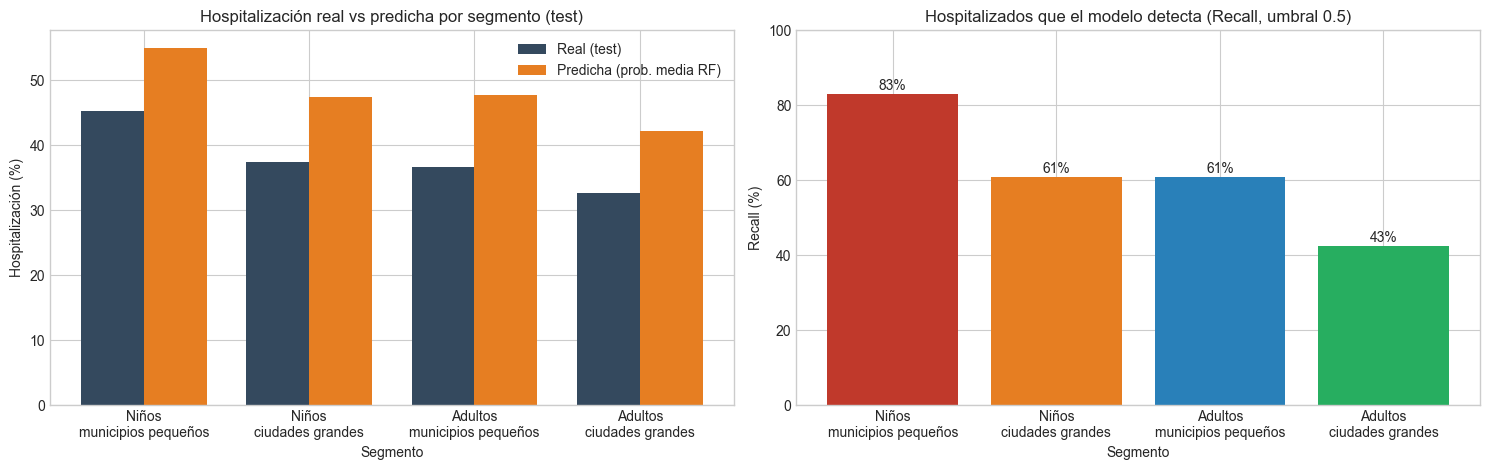

In [23]:
X_rf = limpio.drop(columns=["PAC_HOS", "split"])
y_rf = limpio["PAC_HOS"]
rf_final = RandomForestClassifier(n_estimators=50, max_depth=15, min_samples_leaf=1,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
rf_final.fit(X_rf[es_train], y_rf[es_train])

proba_test = rf_final.predict_proba(X_rf[~es_train])[:, 1]
pred_test = (proba_test >= 0.5).astype(int)
test_seg = perfil_base[~es_train].assign(proba=proba_test, pred=pred_test)
print(f"Random Forest sobre datos_limpios.parquet -> ROC-AUC test: {roc_auc_score(y_rf[~es_train], proba_test):.3f} | "
      f"Recall test: {recall_score(y_rf[~es_train], pred_test):.3f}")

por_seg = test_seg.groupby("cluster").apply(lambda g: pd.Series({
    "casos_test": len(g),
    "tasa_real": g["hospitalizado"].mean(),
    "proba_media": g["proba"].mean(),
    "pct_alertas": g["pred"].mean(),
    "recall": recall_score(g["hospitalizado"], g["pred"]),
    "auc": roc_auc_score(g["hospitalizado"], g["proba"]),
}), include_groups=False).loc[perfil.index]
por_seg.insert(0, "segmento", por_seg.index.map(NOMBRES))
display(por_seg.style.format({"casos_test": "{:,.0f}", "tasa_real": "{:.1%}", "proba_media": "{:.1%}",
                              "pct_alertas": "{:.1%}", "recall": "{:.1%}", "auc": "{:.3f}"}))

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(por_seg))
ancho = 0.38
etiquetas = [CORTOS[c].replace(" · ", "\n") for c in por_seg.index]
ejes[0].bar(x - ancho / 2, por_seg["tasa_real"] * 100, ancho, label="Real (test)", color="#34495e")
ejes[0].bar(x + ancho / 2, por_seg["proba_media"] * 100, ancho, label="Predicha (prob. media RF)", color="#e67e22")
ejes[0].set_xticks(x, etiquetas)
ejes[0].set(title="Hospitalización real vs predicha por segmento (test)", xlabel="Segmento",
            ylabel="Hospitalización (%)")
ejes[0].legend()
ejes[1].bar(x, por_seg["recall"] * 100, color=[colores[c] for c in por_seg.index])
for i, v in enumerate(por_seg["recall"]):
    ejes[1].text(i, v * 100 + 1, f"{v:.0%}", ha="center")
ejes[1].set_xticks(x, etiquetas)
ejes[1].set(title="Hospitalizados que el modelo detecta (Recall, umbral 0.5)", xlabel="Segmento",
            ylabel="Recall (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

**Insight:** El modelo ordena bien los segmentos: predice más hospitalización justo donde la hay (45% real en niños de municipios pequeños frente a 33% en adultos de ciudades grandes), aunque sus probabilidades quedan unos 10 puntos por encima de lo real en todos los grupos por el `class_weight` usado contra el desbalance; sirven para **priorizar**, no como porcentaje exacto. Su capacidad para detectar hospitalizados cambia mucho por segmento: con umbral 0.5 encuentra el 83% en niños de municipios pequeños pero solo el 43% en adultos de ciudades grandes, donde perdería más de la mitad de los casos. Como el AUC dentro de cada segmento es parecido (0.70-0.72), la diferencia viene de la tasa base de cada grupo y no de que el modelo funcione peor; si se usa en la práctica, conviene un umbral más bajo para los adultos de ciudades grandes.

### 16.2 Conclusiones del proyecto

**Hallazgos del EDA (Fase A)**
- El dengue en 2022-2025 se concentra en niños y jóvenes (mediana de edad ~17 años, pico entre 5 y 12) y en pocos departamentos, encabezados por Valle del Cauca.
- La epidemia no es estable: 2024 fue un brote atípico, con picos entre las semanas 15 y 25, y la tasa de hospitalización registrada bajó del 53% en 2022 a ~35% en 2024-25 (deriva temporal).
- La hospitalización tiene forma de U según la edad (más alta en menores de 1 año y mayores de 70), como corrigió la Fase B.

**Limpieza y preparación (Fase B)**
- Casi no había nulos reales; el problema eran los nulos disfrazados (`estrato` en blanco o "SIN DATO", 4%), las edades en unidades mezcladas y las variables posteriores a la notificación (`AJUSTE`, `nom_est_f_caso`), que se excluyeron para no "hacer trampa".
- El split se hizo primero y toda imputación, codificación y escalado se ajustó solo con train, con verificación anti-leakage.

**Modelos (Fase C)**
- *Supervisado:* el mejor modelo (Random Forest) discrimina de forma **moderada** (ROC-AUC ≈ 0.71 en test sobre `datos_limpios.parquet`). Sirve para priorizar pacientes, no para decidir una hospitalización: con umbral 0.5 detecta ~65% de los hospitalizados.
- *No supervisado:* K-Means divide a los pacientes en 4 segmentos por edad y tamaño del municipio. El de **niños y adolescentes de municipios pequeños** concentra la mayor hospitalización (45% frente a 38% promedio) y es donde el modelo detecta mejor los casos; los **adultos de ciudades grandes** se hospitalizan menos (33%) y el modelo pierde más de la mitad de sus hospitalizaciones.

**Efectividad y uso recomendado**
- Ningún modelo es suficientemente preciso para uso clínico individual; su valor está en **orientar recursos**: priorizar seguimiento y capacidad hospitalaria en municipios pequeños con muchos casos infantiles, y ajustar el umbral de alerta por segmento.
- La segmentación es débil (Silhouette ≈ 0.18): los grupos son cortes de un continuo, útiles para comunicar y planear, no tipos de paciente bien diferenciados.

**Mejoras sugeridas**
1. **Más datos y variables:** población DANE por municipio (para calcular tasas reales y no solo conteos), clima (lluvia y temperatura) y variables clínicas disponibles al momento de la consulta (signos de alarma, comorbilidades).
2. **Validación temporal:** entrenar con años anteriores y evaluar con el siguiente, por la deriva de 2022 a 2025.
3. **Modelos e hiperparámetros:** búsqueda más amplia, Gradient Boosting y calibración de probabilidades para que el porcentaje predicho sea interpretable.
4. **Clustering:** dar el mismo peso a variables continuas y categóricas (por ejemplo, K-Prototypes o Gower) para que sexo, etnia o grupos poblacionales influyan en los segmentos.